In [ ]:
import numpy as np
import pandas as pd

from kneed import KneeLocator
from shap import TreeExplainer
import matplotlib.pyplot as plt

from utilities import explain_instance, Monte_Carlo_Splitting, Feature_Selection
from utilities import get_understandable_features, feature_importance

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import RobustScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Import Data
df = pd.read_csv("Understandability_Scores_Processed.csv", index_col= 0)

#Filter for only medical data
df = df[df['Dataset'] == 1]

#Import Understandability Scores
df_med = pd.read_csv("Medical.csv", index_col=0)

#Drop Oral since it has 0 variance
df_med.drop('oral', axis = 1, inplace = True)

#Replace df 'height' value to make naming conventions consistent
df = df.replace('height', 'height(cm)')
df = df.replace('waist', 'waist(cm)')
df = df.replace('weight', 'weight(kg)')
df = df.replace('Age', 'age')

Step 1: Monte Carlo Splitting to establish consistent accuracy across splits

Now let's apply the pipeline to the medical data

In [2]:
#Call Monte Carlo For the Medical Data
n_runs = 50

#Define Data and Hyperparameters Here
X = df_med.drop('smoking', axis = 1)
y = df_med['smoking']

cat_features = ["gender", "tartar", "dental caries", "hearing(left)", "hearing(right)"]
num_features = [x for x in X.columns if x not in cat_features]

preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features) #Change this depending on dataset
],
remainder='passthrough')

acc_out, f1_out, p_out, r_out = Monte_Carlo_Splitting(X, y, 0.3, preprocessor, n_runs)
    
#Save lists to output just in case
df_out = pd.DataFrame().from_dict({'Accuracy' : acc_out, 'F1' : f1_out, 'Precision' : p_out, 'Recall' : r_out})
df_out.to_csv('Output_Monte_Carlo_Sampling_Medical.csv')

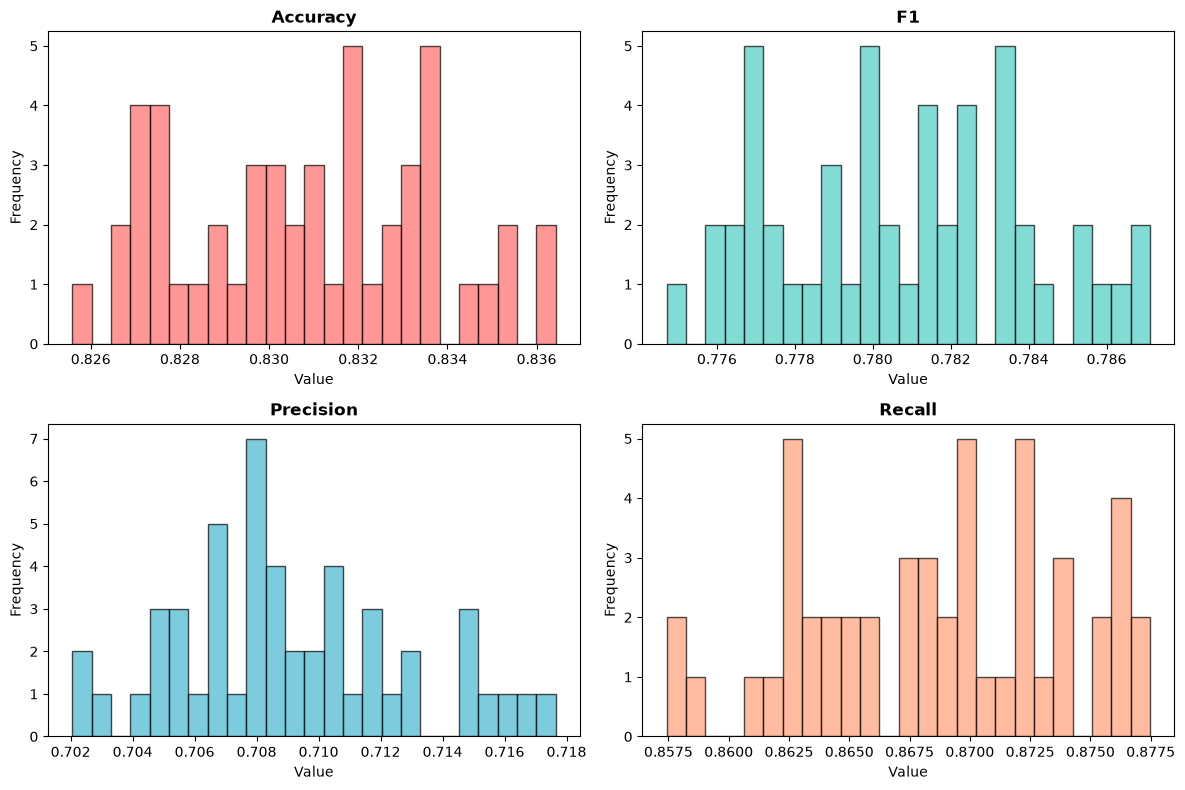

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']
columns = df_out.columns

for idx, (ax, col, color) in enumerate(zip(axs.flat, columns, colors)):
    ax.hist(df_out[col], bins=25, color=color, edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Step 1 - done!

Step 2: Build Feature Selection mechanism.

In [2]:
def model_implementation(data, seed_n, numeric_features, categorical_features):
    """Implements the ML model and returns the performance and feature importances"""
    #Split Data
    X = data.drop('Output', axis = 1)
    y = data['Output']
    
    #Subset numerical and categorical features
    numeric_features = [x for x in numeric_features if x in data.columns.tolist()]
    categorical_features = [x for x in categorical_features if x in data.columns.tolist()]
    
    #Implement train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed_n)
    
    #Implement preprocessing
    preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numeric_features),
        ('cat', OrdinalEncoder(handle_unknown='error'), categorical_features)
    ],
    remainder='passthrough')
    
    #Fit preprocessing
    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)
    
    #Get column names
    feature_names = preprocessor.get_feature_names_out()

    #Transform Back to df
    X_train = pd.DataFrame(X_train, columns=feature_names, index=None)
    X_test = pd.DataFrame(X_test, columns=feature_names, index=None)
    
    parameters = {'max_depth' : [1, 2, 3, 4],
            'min_samples_split': [2, 3, 4],
            'min_samples_leaf': [3, 4, 5],
            'criterion' : ['gini', 'entropy'],
            'class_weight' : ['balanced']}

    grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=seed_n), param_grid=parameters, cv=StratifiedKFold(5), scoring='balanced_accuracy', n_jobs=-1)
    
    grid_search.fit(X_train,
                    y_train)
    
    print(grid_search.best_params_)
    
    best_model = grid_search.best_estimator_
    
    best_model.fit(X_train, y_train)
    
    y_pred = best_model.predict(X_test)
    
    acc = balanced_accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    
    #Get shap values
    feature_importance_df = feature_importance(best_model, X_train, X_test, y_test, 20, preprocessor, numeric_features, categorical_features)
    
    return acc, f1, precision, recall, grid_search.best_score_, feature_importance_df, best_model, X_train, X_test, y_test, preprocessor

In Co_Op


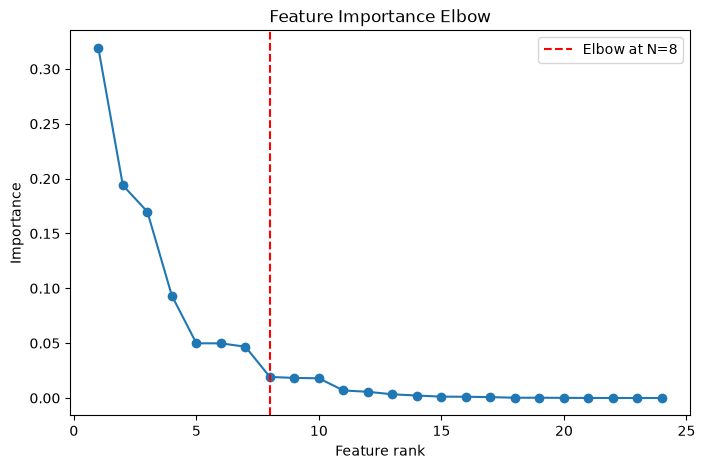

{'AST': 3.2016129032258065, 'hemoglobin': 3.8306451612903225, 'dental caries': 3.352380952380952, 'urine protein': 3.786290322580645, 'Gtp': 2.943548387096774, 'relaxation': 3.1035714285714286, 'weight(kg)': 3.99609375, 'serum creatinine': 3.4827586206896552, 'LDL': 3.5991379310344827, 'ALT': 3.1510416666666665, 'systolic': 3.635, 'Cholesterol': 4.004166666666666, 'hearing (left)': 3.1979166666666665, 'eyesight (right)': 3.5845588235294117, 'triglyceride': 3.3529411764705883, 'hearing (right)': 3.1313131313131324, 'fasting blood sugar': 3.6847826086956523, 'HDL': 3.3161764705882355, 'tartar': 3.591397849462365, 'gender': 3.7692307692307696, 'eyesight (left)': 3.3981481481481484, 'height(cm)': 3.668103448275862, 'waist(cm)': 3.5859375, 'age': 3.6785714285714284}
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}
Co-Optimised Feature Selection with five features: 
 Final CV Accuracy:  0.7575968596798316 
 Final Accuracy:  0.75

In [9]:
#import data and define hyperparameters
X = df_med.drop('smoking', axis=1)
y = df_med['smoking']
cat_features = ["gender", "tartar", "dental caries", "hearing(left)", "hearing(right)"]
num_features = [x for x in X.columns if x not in cat_features]
seed = 42

#Define Preprocessor
preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features)
],
remainder='passthrough')

selected_features, n_optimal, sorted_importances, sorted_names = Feature_Selection(X, y, seed, preprocessor, True, 5, plot = True, strictness=12)
final_features, dict_selected, df_final = get_understandable_features(selected_features, df, 5, df_med, 'smoking')

(final_acc_coop, final_f1_coop, final_precision_coop, final_recall_coop, final_grid_acc,
importances_coop, trained_model, X_train, X_test, y_test, preprocessor) = model_implementation(
    df_final, seed, num_features, cat_features
)

print("Co-Optimised Feature Selection with five features: \n",
    "Final CV Accuracy: ", final_grid_acc, '\n',
    "Final Accuracy: ", final_acc_coop, '\n'
    "Final F1: ", final_f1_coop, '\n'
    "Final Precision: ", final_precision_coop, '\n'
    "Final Recall: ", final_recall_coop, '\n'
    "Features Selected: ", final_features)

# This IS the shap_df now — no need to call feature_importance() again
class_labels = {0: "be a non-smoker", 1: "be a smoker"}

#Get DF of explanations
records = []
for x in range(20):
    records.append({
        "instance_id": x,
        "explanation": explain_instance(x, importances_coop, class_labels, top_n=5)
    })

explanation_df_coop_med = pd.DataFrame(records)
print("Average Understandability: ", sum([dict_selected[x] for x in final_features])/5)
# explanation_df_coop_med.to_csv('Explanations_CoOp_Med.csv', index=False)

In [10]:
X = df_med.drop('smoking', axis=1)
y = df_med['smoking']
cat_features = ["gender", "tartar", "dental caries", "hearing(left)", "hearing(right)"]
num_features = [x for x in X.columns if x not in cat_features]
seed = 42

preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features)
],
remainder='passthrough')

selected_features, n_optimal, sorted_importances, sorted_names = Feature_Selection(X, y, seed, preprocessor, False, 5)
final_features, dict_selected, df_final = get_understandable_features(selected_features, df, 5, df_med, 'smoking')

(final_acc_trad, final_f1_trad, final_precision_trad, final_recall_trad, final_grid_acc_trad,
importances_trad, trained_model_trad, X_train_trad, X_test_trad, y_test_trad, preprocessor_trad) = model_implementation(
    df_final, seed, num_features, cat_features
)

print("Traditional Feature Selection with five features: \n",
    "Final CV Accuracy: ", final_grid_acc_trad, '\n',
    "Final Accuracy: ", final_acc_trad, '\n'
    "Final F1: ", final_f1_trad, '\n'
    "Final Precision: ", final_precision_trad, '\n'
    "Final Recall: ", final_recall_trad, '\n'
    "Features Selected: ", final_features)

# This IS the shap_df now — no need to call feature_importance() again
class_labels = {0: "be a non-smoker", 1: "be a smoker"} 

#Get DF of explanations
records = []
for x in range(20):
    records.append({
        "instance_id": x,
        "explanation": explain_instance(x, importances_trad, class_labels, top_n=5)
    })

explanation_df_trad_med = pd.DataFrame(records)
print("Average Understandability: ", sum([dict_selected[x] for x in final_features])/5)
# explanation_df_trad_med.to_csv('Explanations_Trad_Med.csv', index=False)

In Trad
{'AST': 3.2016129032258065, 'hemoglobin': 3.8306451612903225, 'dental caries': 3.352380952380952, 'urine protein': 3.786290322580645, 'Gtp': 2.943548387096774, 'relaxation': 3.1035714285714286, 'weight(kg)': 3.99609375, 'serum creatinine': 3.4827586206896552, 'LDL': 3.5991379310344827, 'ALT': 3.1510416666666665, 'systolic': 3.635, 'Cholesterol': 4.004166666666666, 'hearing (left)': 3.1979166666666665, 'eyesight (right)': 3.5845588235294117, 'triglyceride': 3.3529411764705883, 'hearing (right)': 3.1313131313131324, 'fasting blood sugar': 3.6847826086956523, 'HDL': 3.3161764705882355, 'tartar': 3.591397849462365, 'gender': 3.7692307692307696, 'eyesight (left)': 3.3981481481481484, 'height(cm)': 3.668103448275862, 'waist(cm)': 3.5859375, 'age': 3.6785714285714284}
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}
Traditional Feature Selection with five features: 
 Final CV Accuracy:  0.7561005393488933 
 Final Accur

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

def compute_descriptives(path, out_path):
    df = pd.read_csv(path, index_col=0)
    n = len(df)
    mean = df.mean()
    sd = df.std(ddof=1)                  # sample SD (pandas default is already ddof=1)
    se = sd / np.sqrt(n)
    t_crit = stats.t.ppf(0.975, df=n - 1)

    result = pd.DataFrame({
        'Mean': mean,
        'Standard Deviation': sd,
        'Lower 95% CI': mean - t_crit * se,
        'Higher 95% CI': mean + t_crit * se
    })
    result.to_csv(out_path)
    return result

df_med_final = compute_descriptives(
    'Output_Monte_Carlo_Sampling_Medical.csv',
    'Descriptive_Monte_Carlo_Sampling_Med.csv'
)

df_phone_final = compute_descriptives(
    'Output_Monte_Carlo_Sampling_Phone.csv',
    'Descriptive_Monte_Carlo_Sampling_Phone.csv'
)

In [4]:
round(df_phone_final, 3)

,Mean,Standard Deviation,Lower 95% CI,Higher 95% CI
Accuracy,0.733,0.009,0.731,0.736
F1,0.603,0.013,0.600,0.607
Precision,0.569,0.013,0.565,0.573
Recall,0.642,0.020,0.637,0.648
